In [9]:
import os
import sys

from matplotlib import pyplot as plt
import matplotlib.patches as mpatch
import numpy as np
from scipy.integrate import dblquad
from scipy.stats import multivariate_normal

CWD = os.path.abspath("")
sys.path.append(os.path.join(CWD, ".."))

plt_settings = {"font.size": 7}

full_width = 5.5
ratio = 1 / 1.618

In [10]:
A, B = 0.5, 2.0


def ellipse(p, a, b):
    return p[..., 0] ** 2 / a**2 + p[..., 1] ** 2 / b**2

In [11]:
ITERATIONS = int(5e6)
BURN_IN = int(4e6)

sampling_data = np.load(os.path.join(CWD, "2d_gaussian.npz"))

pdlmc_samples_all = sampling_data["pdlmc_x"]
pdlmc_samples = pdlmc_samples_all[BURN_IN:]
pdlmc_lambda = sampling_data["pdlmc_lambda"]
rejection_samples = sampling_data["rejection_x"]

In [12]:
# True mean
y_max = lambda x: B * np.sqrt(1 - x**2 / A**2)

Z, _ = dblquad(
    lambda y, x: multivariate_normal.pdf([x, y], mean=np.ones(2) * 2),
    -A,
    A,
    lambda x: -y_max(x),
    y_max,
)
true_mean_x, _ = dblquad(
    lambda y, x: x * multivariate_normal.pdf([x, y], mean=np.ones(2) * 2),
    -A,
    A,
    lambda x: -y_max(x),
    y_max,
)
true_mean_y, _ = dblquad(
    lambda y, x: y * multivariate_normal.pdf([x, y], mean=np.ones(2) * 2),
    -A,
    A,
    lambda x: -y_max(x),
    y_max,
)

true_mean = np.array([true_mean_x / Z, true_mean_y / Z])
print(f"Probability mass of the Gaussian inside the ellipse (Z): {Z:.4f}")
print(f"Mean of the distribution: {true_mean}")

# Estimated mean
pdlmc_mean = pdlmc_samples.mean(axis=0)
rejection_mean = rejection_samples.mean(axis=0)

print(f"Estimated mean via PD-LMC: {pdlmc_mean}")
print(f"Estimated mean via rejection: {rejection_mean}")

# Out-of-support samples
out_of_support = (ellipse(pdlmc_samples, A, B) > 1).mean()
print(f"Percentage of out-of-support samples: {out_of_support * 100:.2f}%")

# overestimation of boundary
pdlmc_samples_norm = ellipse(pdlmc_samples, A, B)
pdlmc_boundary = np.logical_and(pdlmc_samples_norm >= 1 - 1e-3, pdlmc_samples_norm <= 1).mean()
rejection_boundary = (ellipse(rejection_samples, A, B) >= 1 - 1e-3).mean()

print(f"PD-LMC - Percentage of samples on boundary: {pdlmc_boundary * 100:.2f}%")
print(f"Rejection - Percentage of samples on boundary: {rejection_boundary * 100:.2f}%")

Probability mass of the Gaussian inside the ellipse (Z): 0.0204
Mean of the distribution: [0.10155644 1.01212655]
Estimated mean via PD-LMC: [0.10228541 1.02386263]
Estimated mean via rejection: [0.10151362 1.0122257 ]
Percentage of out-of-support samples: 3.22%
PD-LMC - Percentage of samples on boundary: 0.09%
Rejection - Percentage of samples on boundary: 0.14%


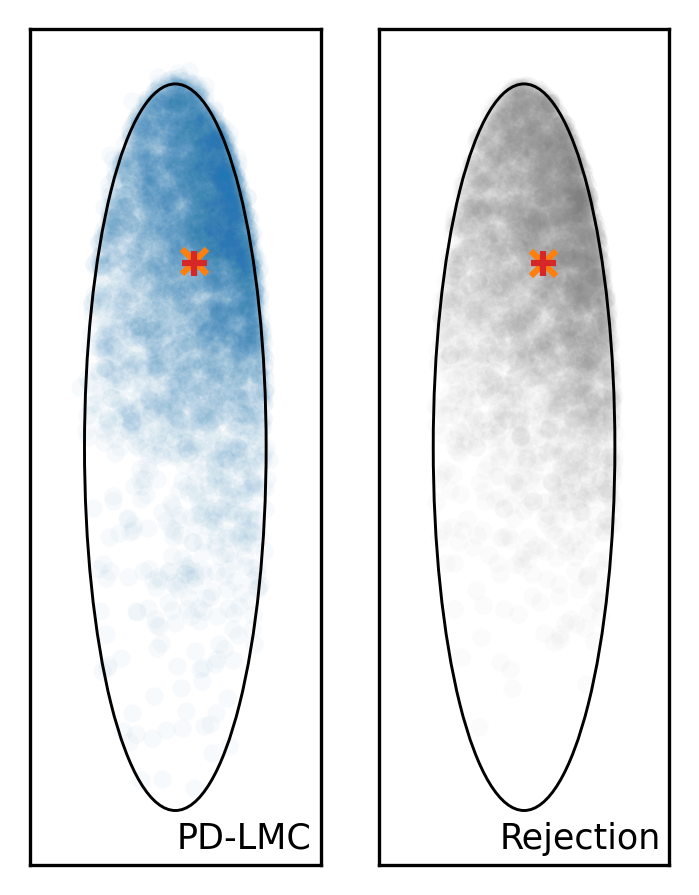

In [13]:
plt_settings["figure.figsize"] = (full_width / 2, full_width * 0.7)
scatter_kwargs = {
    "s": 20.0,
    "edgecolors": "face",
    "alpha": 0.03,
    "linewidth": 0.0,
}

with plt.rc_context(plt_settings):
    _, axs = plt.subplots(1, 2, dpi=300)
    axs[0].scatter(pdlmc_samples[::200, 0], pdlmc_samples[::200, 1], **scatter_kwargs)
    axs[1].scatter(
        rejection_samples[::1000, 0], rejection_samples[::1000, 1], c="grey", **scatter_kwargs
    )

    for i, m in enumerate([pdlmc_mean, rejection_mean]):
        axs[i].scatter([m[0]], [m[1]], marker="x", color="C1", label="Estimated mean")
        axs[i].scatter([true_mean[0]], [true_mean[1]], marker="+", color="C3", label="True mean")

    # Ellipse
    for ax in axs:
        ax.add_artist(
            mpatch.Ellipse((0.0, 0.0), 2 * A, 2 * B, facecolor="none", edgecolor="k", lw=0.7)
        )
        ax.set_xlim((-A - 0.3, A + 0.3))
        ax.set_ylim((-B - 0.3, B + 0.3))
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_aspect(1)
        ax.grid()

    # Title
    for i, label in enumerate(["PD-LMC", "Rejection"]):
        axs[i].set_title(label, loc="right", x=0.97, y=0.02, pad=0)

    plt.show()

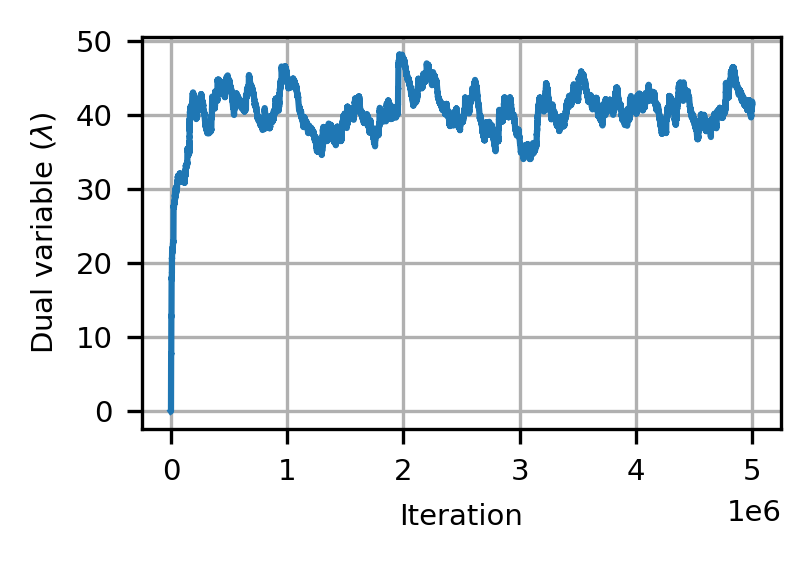

In [14]:
plt_settings["figure.figsize"] = (full_width / 2, ratio * full_width / 2)

with plt.rc_context(plt_settings):
    _, axs = plt.subplots(1, 1, dpi=300)
    axs.plot(pdlmc_lambda)
    axs.grid()
    axs.set_xlabel("Iteration")
    axs.set_ylabel(r"Dual variable ($\lambda$)")

    plt.show()

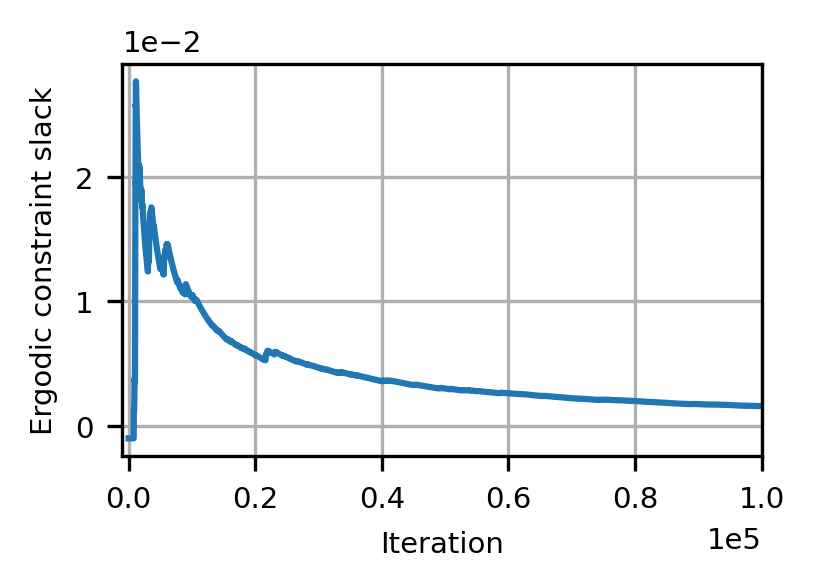

In [15]:
plt_settings["figure.figsize"] = (full_width / 2, ratio * full_width / 2)

with plt.rc_context(plt_settings):
    _, axs = plt.subplots(1, 1, dpi=300)
    cum_mean = np.cumsum(
        np.clip(ellipse(pdlmc_samples_all, A, B) - 1.0, 0.0, None) - 0.001
    ) / np.arange(1, len(pdlmc_samples_all) + 1)
    axs.plot(cum_mean)
    axs.set_xlim((-1e3, 1e5))
    axs.grid()
    axs.set_xlabel("Iteration")
    axs.set_ylabel(r"Ergodic constraint slack")
    axs.ticklabel_format(scilimits=(-2, 2))

    plt.show()

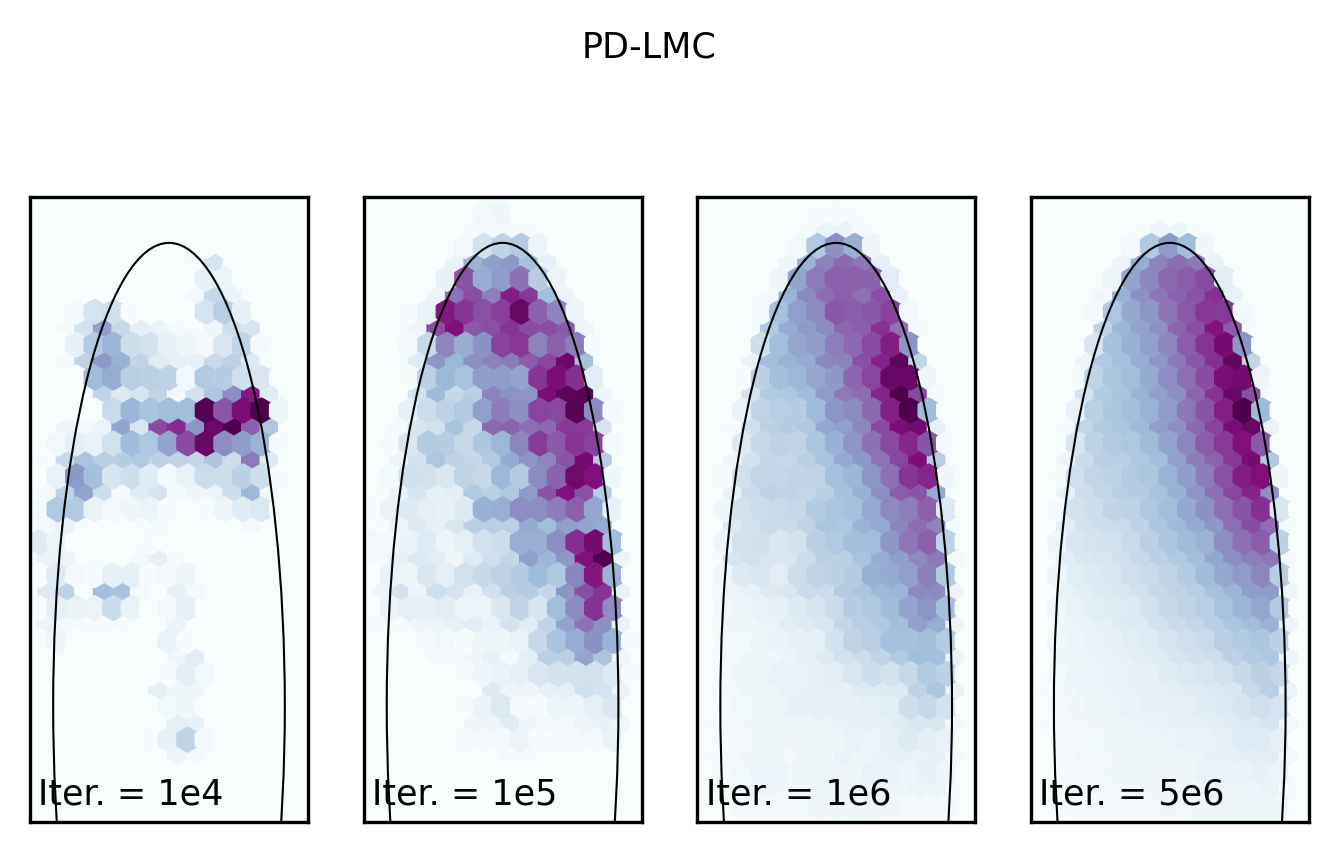

In [16]:
plt_settings["figure.figsize"] = (full_width, full_width * 0.6)

with plt.rc_context(plt_settings):
    fig, axs = plt.subplots(1, 4, dpi=300)
    iters = [10_000, 100_000, 1_000_000, 5_000_000]
    iters_label = ["1e4", "1e5", "1e6", "5e6"]
    for idx, ax in enumerate(axs.reshape(-1)):
        samples = pdlmc_samples_all[: iters[idx]]
        ax.hexbin(
            samples[:, 0],
            samples[:, 1],
            gridsize=(15, 19),
            cmap="BuPu",
            extent=(-0.6, 0.6, -0.5, 2.2),
        )
        ax.add_artist(
            mpatch.Ellipse((0.0, 0.0), 2 * A, 2 * B, facecolor="none", edgecolor="k", lw=0.5)
        )
        ax.set(xlim=(-0.6, 0.6), ylim=(-0.5, 2.2))
        ax.set_title(f"Iter. = {iters_label[idx]}", loc="left", x=0.03, y=0.03, pad=0)
        ax.set_aspect(1.0)
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle("PD-LMC")

    plt.show()